# Speeding up the objective function calculation using numba

The objective function is evaluated over and over again and it makes sense to spent some time to make it faster. Here we use the just-in-time compilation option from `numba`.


## The n-Queens Problem

* __Goal:__ Find an arrangement of $n$ queens on a $n \times n$ chess board so that no queen is on the same row, column or diagonal as any other queen.

* __State space:__ An arrangement of the queens on the board. We restrict the state space to arrangements where there is only a single queen per column. We represent a state as an integer vector $\mathbf{q} = \{q_1, q_2, \dots, q_n\}$, each number representing the row positions of the queens from left to right. We will call a state a "board."

* __Objective function:__ The number of pairwise conflicts (i.e., two queens in the same row/column/diagonal).
The optimization problem is to find the optimal arrangement $\mathbf{q}^*$ of $n$ queens on the board can be written as:

  > minimize: $\mathrm{conflicts}(\mathbf{q})$
  >
  > subject to: $\mathbf{q} \ \text{contains only one queen per column}$

  Note: the constraint (subject to) is enforced by the definition of the state space.

* __Local improvement move:__ Move one queen to a different row in its column.

* __Termination:__ For this problem there is always an arrangement $\mathbf{q}^*$ with $\mathrm{conflicts}(\mathbf{q}^*) = 0$, however, the local improvement moves might end up in a local minimum. 

## Objective function calculation

### Naive $O(n^2)$ Implementation
Naive implementation with nested loops. This is $O(n^2)$.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import colors
import math

In [2]:
def conflicts_naive(board):
    """Calculate the number of conflicts, i.e., the objective function."""
    
    board = np.array(board)
    
    n = len(board)
    val = 0

    # check horizontal (we do not check vertical since the state space is restricted to one queen per col)
    for i in range(n): val += math.comb(np.sum(board == i), 2)
    #print(f"Horizontal value: {val}")
    
    # check for each queen diagonally up and down (only to the right side of the queen)
    for j in range(n):
        q_up = board[j]
        q_down = board[j]
     
        for jj in range(j+1, n):
            q_up -= 1
            q_down += 1
            if board[jj] == q_up: val += 1
            if board[jj] == q_down: val += 1
        #print(f"Value after queen {j}: {val}")
       
    return(val)    

### $O(n)$ Implementation

A better implementation that should be $O(n)$. Idea: 

1. Count how many queens are in each row (no need to check columns) and how many are in each diagonal.
2. Convert the number of $n$ queens in a row (diagonal) into the numbner of pariwise conflicts in $n$ choose 2. We use a faster special case for the `comb()` function to calcualte the conflicts given the number of queens.   

In [3]:
def comb2(n): return n*(n-1)//2 # this is n choose 2 equivalent to math.comb(n, 2); // is int division

def conflicts(board):
    """Calculate the number of conflicts, i.e., the objective function."""

    n = len(board)
    
    horizontal_cnt = [0] * n
    # we have double the diagonals compared to columns!
    diagonal1_cnt = [0] * 2 * n
    diagonal2_cnt = [0] * 2 * n
    
    for i in range(n):
        horizontal_cnt[board[i]] += 1
        diagonal1_cnt[i + board[i]] += 1
        diagonal2_cnt[i - board[i] + n] += 1
    
    return sum(map(comb2, horizontal_cnt + diagonal1_cnt + diagonal2_cnt))

### Compiled $O(n)$ Implementation
We can use just-in-time compilation for the conflicts function. Code provided by Troy McNitt.

In [4]:
from numba import njit

# with jit (cannot use some Python functions like sum and map)
@njit()
def comb2_jit(n): return n*(n-1)//2 # this is n choose 2 equivalent to math.comb(n, 2); // is int division

@njit()
def conflicts_jit(board):
    """Calculate the number of conflicts, i.e., the objective function."""

    n = len(board)
 
    cnt = [0] * (5 * n)
 
    for i in range(n):
        cnt[board[i]] += 1
        cnt[(n) + (i + board[i])] += 1
        cnt[(3 * n) + (i - board[i] + n)] += 1
 
    conflicts = 0
    for x in cnt:
        conflicts += comb2_jit(x)
 
    return conflicts

# Compare Timing

Compare runtime on 50 random boards of different sizes.

In [5]:
np.random.seed(1234)
def random_board(n):
    """Creates a random board of size n x n. Note that only a single queen is placed in each column!"""
    
    return(np.random.randint(0,n, size = n))

In [6]:
import timeit
 
# run it once to force compilation
conflicts_jit(random_board(4))
    
reps = 20
x = []
naive_times = []
linear_times = []
jit_times = []
 
 
for i in [8] + list(range(50, 500, 50)):
    # do reps replications on random boards
    boards = [random_board(i) for _ in range(reps)]
 
    #print(f"Doing: {i}")

    # number = 1 means we only run it once in timeit 
    naive = timeit.timeit(
        lambda: [conflicts_naive(board) for board in boards], number=1
    )
    linear = timeit.timeit(
        lambda: [conflicts(board) for board in boards], number=1
    )
    jit = timeit.timeit(
        lambda: [conflicts_jit(board) for board in boards], number=1
    )

 
    x.append(i)
    naive_times.append(naive)
    linear_times.append(linear)
    jit_times.append(jit)

# average time per board in microseconds
naive_times = np.array(naive_times) / reps * 1e6
linear_times = np.array(linear_times) / reps * 1e6
jit_times = np.array(jit_times) / reps * 1e6

print("Times for 8x8 board in microseconds")
print(f'naive: {naive_times[0]}, linear: {linear_times[0]}, jit: {jit_times[0]}')
 

Times for 8x8 board in microseconds
naive: 141.2002999984452, linear: 33.57465000135562, jit: 2.168950004488579


In [7]:
for n_, a, b, c in zip(x, naive_times, linear_times, jit_times):
    print(f"{n_}: naive={a:.1f}, linear={b:.1f}, jit={c:.2f}")

8: naive=141.2, linear=33.6, jit=2.17
50: naive=1656.9, linear=138.3, jit=4.02
100: naive=4327.3, linear=132.5, jit=4.61
150: naive=4873.9, linear=160.2, jit=3.97
200: naive=8482.6, linear=221.9, jit=4.75
250: naive=12564.3, linear=284.8, jit=5.67
300: naive=24336.9, linear=326.5, jit=6.45
350: naive=32857.5, linear=428.6, jit=7.00
400: naive=31527.7, linear=469.9, jit=10.61
450: naive=52544.1, linear=652.6, jit=8.35


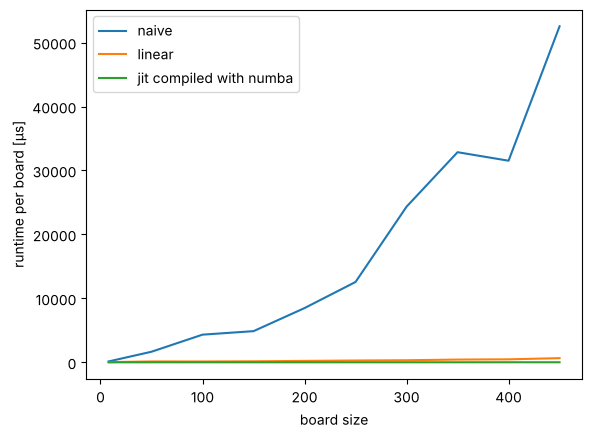

In [8]:
plt.plot(x, naive_times)
plt.plot(x, linear_times)
plt.plot(x, jit_times)
plt.xlabel("board size")
plt.ylabel("runtime per board [µs]")
plt.legend(["naive", "linear", "jit compiled with numba"])
plt.show()

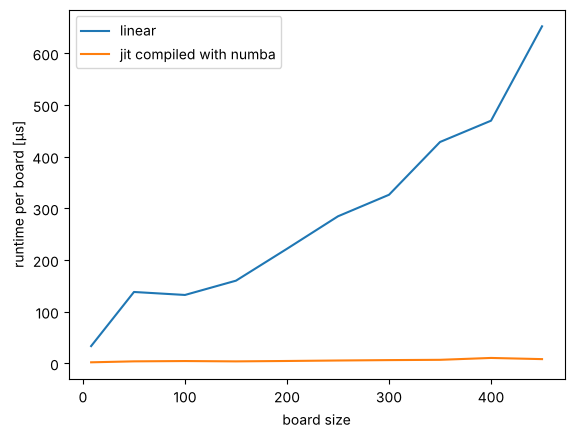

In [9]:
plt.plot(x, linear_times)
plt.plot(x, jit_times)
plt.xlabel("board size")
plt.ylabel("runtime per board [µs]")
plt.legend(["linear", "jit compiled with numba"])
plt.show()

## Bài 6 – Giải thích và nhận xét

**Vì sao đếm theo hàng/đường chéo thay vì so sánh từng cặp quân hậu?** Hai quân hậu xung đột nếu cùng hàng hoặc cùng đường chéo. Nếu có $k$ quân hậu trên cùng một hàng (hoặc đường chéo), chúng tạo ra $\binom{k}{2} = k(k-1)/2$ cặp xung đột. Do đó chỉ cần *đếm* số quân hậu trên mỗi hàng, mỗi đường chéo "/" (chỉ số `i + board[i]`) và mỗi đường chéo "\" (chỉ số `i - board[i] + n`) trong một lượt duyệt $n$ quân hậu, rồi cộng $\binom{k}{2}$ của các ô đếm: $f(\text{board}) = \sum C(k, 2)$. Có $n$ hàng và $2n$ đường chéo mỗi loại nên tổng chi phí là $O(n)$, thay vì so sánh $\binom{n}{2}$ cặp quân hậu của cách làm ngây thơ, tức $O(n^2)$.

**Vì sao cần chạy `conflicts_jit()` một lần trước khi đo?** `@njit` biên dịch hàm ở *lần gọi đầu tiên* (just-in-time). Lần gọi đầu tiên vì thế bao gồm cả thời gian biên dịch (hàng trăm ms), lớn hơn nhiều so với thời gian chạy thực của hàm. Nếu không "làm nóng" bằng một lần gọi trước, thời gian biên dịch sẽ bị tính vào phép đo và làm sai lệch kết quả so sánh tốc độ; vì vậy notebook gọi `conflicts_jit(random_board(4))` trước vòng đo.

**Đọc đồ thị.** Đường *naive* tăng theo $n^2$ (parabol) và rất nhanh vượt xa hai đường còn lại; đường *linear* tăng theo $n$ (gần như đường thẳng); đường *jit* cũng tăng tuyến tính nhưng với hệ số góc rất nhỏ do mã máy được biên dịch (không còn chi phí thông dịch của Python). Lợi ích của JIT thể hiện ở hệ số hằng (tăng tốc hàng chục lần) chứ không làm đổi bậc $O(n)$. Ngay cả với $n=8$, JIT đã nhanh hơn cách tuyến tính khoảng 15 lần và cách ngây thơ khoảng 65 lần (141.2 → 33.6 → 2.17 µs); tuy nhiên chênh lệch tuyệt đối chỉ vài chục đến vài trăm µs, nên lợi ích chỉ thật sự đáng kể khi hàm được gọi rất nhiều lần như trong các thuật toán tìm kiếm cục bộ. Ở $n=450$, cách tuyến tính nhanh hơn cách ngây thơ khoảng 80 lần và JIT nhanh hơn cách tuyến tính khoảng 78 lần.

**Nhiễu đo.** Các đường thời gian không hoàn toàn tăng dần: naive ở $n=400$ thấp hơn ở $n=350$, linear ở $n=100$ thấp hơn ở $n=50$, JIT ở $n=150$ thấp hơn ở $n=100$ và ở $n=450$ thấp hơn ở $n=400$. Về lý thuyết thời gian phải tăng theo $n$, nên đây không phải do thuật toán mà do **nhiễu đo**: đoạn mã đo dùng `timeit.timeit(..., number=1)`, tức mỗi trường hợp chỉ được đo *một lần*, trong khi thời gian cần đo rất nhỏ (vài µs đến vài chục ms) nên dễ bị ảnh hưởng bởi các tác vụ khác của hệ điều hành, bộ nhớ đệm CPU hay bộ thu gom rác của Python. Nhiễu không làm thay đổi kết luận chính (naive tăng theo $n^2$, linear và JIT tăng theo $n$, JIT nhanh hơn hàng chục lần) nhưng làm các con số cụ thể kém tin cậy. Mục **Cải tiến phép đo** ở cuối notebook đề xuất cách khắc phục.

## Cải tiến phép đo (đề xuất của nhóm)

**Vấn đề.** Đoạn mã đo ở trên dùng `timeit.timeit(..., number=1)`, tức mỗi cài đặt và mỗi kích thước chỉ được đo **một lần duy nhất**. Ở thang vài micro giây, một lần đo rất dễ bị ảnh hưởng bởi các tác vụ khác của hệ điều hành (lập lịch tiến trình, bộ nhớ đệm CPU, bộ thu gom rác của Python...), nên số liệu có thể dao động và đường thời gian không đơn điệu.

**Cách khắc phục.** Lặp lại mỗi phép đo nhiều lần bằng `timeit.repeat(..., number=1, repeat=15)` và lấy **giá trị nhỏ nhất** (`min`). Giá trị nhỏ nhất ít bị nhiễu nhất vì nhiễu chỉ có thể làm thời gian *tăng* lên chứ không làm giảm; đây cũng là khuyến nghị trong tài liệu của module `timeit`. Ô mã dưới đây đo lại trên **cùng các bàn cờ** và cùng các kích thước để so sánh với cách đo ở trên (mã gốc ở trên được giữ nguyên).


   n | naive (1 lần) naive (min 15) | linear (1 lần) linear (min 15) | jit (1 lần) jit (min 15)
   8 |         141.2           47.7 |           33.6             8.7 |        2.17         0.43
  50 |        1656.9          662.5 |          138.3            51.4 |        4.02         1.15
 100 |        4327.3         2114.3 |          132.5           101.2 |        4.61         1.83
 150 |        4873.9         4474.2 |          160.2           165.3 |        3.97         3.90
 200 |        8482.6         7844.9 |          221.9           215.8 |        4.75         3.19
 250 |       12564.3        11953.7 |          284.8           264.6 |        5.67         3.86
 300 |       24336.9        17961.0 |          326.5           338.2 |        6.45         5.05
 350 |       32857.5        25923.5 |          428.6           391.4 |        7.00         5.23
 400 |       31527.7        32780.4 |          469.9           455.1 |       10.61         5.91
 450 |       52544.1        39049.0 |   

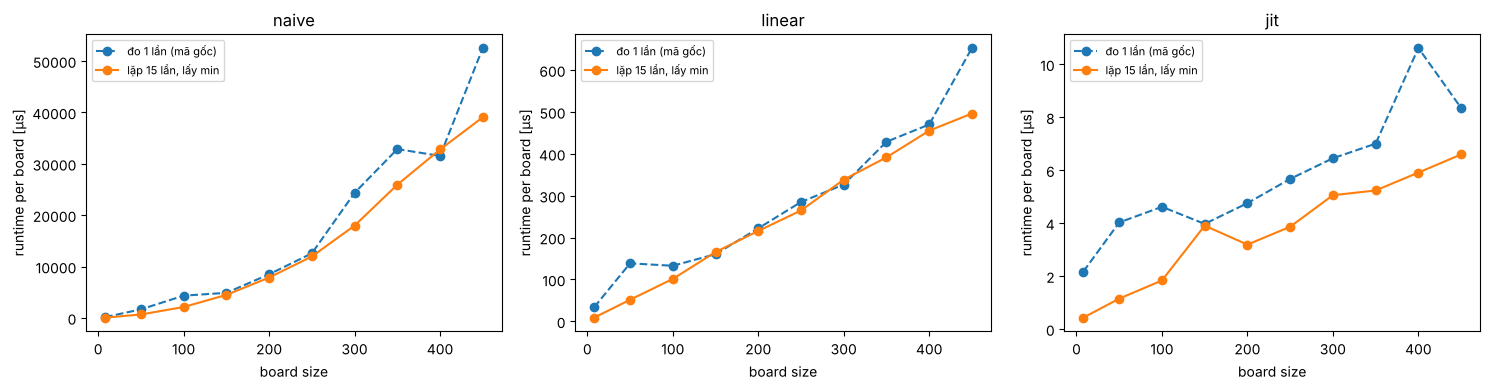

In [10]:
# Đo lại với cùng các kích thước, mỗi phép đo lặp 15 lần và lấy lần nhanh nhất
np.random.seed(1234)
random_board(4)          # giống mã gốc (ô làm nóng JIT) để sinh ra đúng các bàn cờ như ở trên
REPEAT = 15
naive_rep, linear_rep, jit_rep = [], [], []
for i in x:
    boards = [random_board(i) for _ in range(reps)]
    naive_rep.append(min(timeit.repeat(lambda: [conflicts_naive(b) for b in boards], number=1, repeat=REPEAT)))
    linear_rep.append(min(timeit.repeat(lambda: [conflicts(b) for b in boards], number=1, repeat=REPEAT)))
    jit_rep.append(min(timeit.repeat(lambda: [conflicts_jit(b) for b in boards], number=1, repeat=REPEAT)))

naive_rep = np.array(naive_rep) / reps * 1e6      # micro giây trên một bàn cờ
linear_rep = np.array(linear_rep) / reps * 1e6
jit_rep = np.array(jit_rep) / reps * 1e6

def n_drops(t):
    """Số lần thời gian GIẢM khi n tăng (đường đúng ra phải tăng dần)."""
    return int(np.sum(np.diff(t) < 0))

print(f"{'n':>4} | {'naive (1 lần)':>13} {'naive (min 15)':>14} | {'linear (1 lần)':>14} {'linear (min 15)':>15} | {'jit (1 lần)':>11} {'jit (min 15)':>12}")
for k, n_ in enumerate(x):
    print(f"{n_:>4} | {naive_times[k]:>13.1f} {naive_rep[k]:>14.1f} | {linear_times[k]:>14.1f} {linear_rep[k]:>15.1f} | {jit_times[k]:>11.2f} {jit_rep[k]:>12.2f}")
print("\nSố lần đường thời gian bị 'đi xuống' khi n tăng (càng ít càng ổn định):")
for name, a, b in [("naive", naive_times, naive_rep), ("linear", linear_times, linear_rep), ("jit", jit_times, jit_rep)]:
    print(f"  {name:>6}: đo 1 lần = {n_drops(a)},  lặp 15 lần lấy min = {n_drops(b)}")

fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for a_, name, one, rep in [(ax[0], "naive", naive_times, naive_rep), (ax[1], "linear", linear_times, linear_rep), (ax[2], "jit", jit_times, jit_rep)]:
    a_.plot(x, one, "o--", label="đo 1 lần (mã gốc)")
    a_.plot(x, rep, "o-", label="lặp 15 lần, lấy min")
    a_.set_title(name); a_.set_xlabel("board size"); a_.set_ylabel("runtime per board [µs]"); a_.legend(fontsize=8)
plt.tight_layout(); plt.show()


**Nhận xét về cải tiến.** So sánh hai cách đo trên cùng các bàn cờ (bảng và biểu đồ ở trên):

* **Đường thời gian ổn định hơn.** Số lần thời gian bị "đi xuống" khi $n$ tăng giảm từ 1 xuống 0 với naive, từ 1 xuống 0 với linear và từ 2 xuống 1 với JIT. Với naive và linear, đường thời gian giờ đã tăng đều theo $n$ đúng như lý thuyết.
* **Số đo sát thời gian thực hơn.** Giá trị nhỏ nhất loại bỏ phần thời gian bị nhiễu cộng thêm, nên nhỏ hơn đáng kể khi hàm chạy rất nhanh: với $n=8$, JIT đo một lần ra 2.17 µs nhưng lặp 15 lần chỉ còn 0.43 µs (cách đo một lần bị nhiễu làm chậm khoảng 5 lần).
* **Kết luận không đổi, chỉ chắc chắn hơn.** Với cách đo mới: ở $n=8$ JIT nhanh hơn linear khoảng 20 lần và nhanh hơn naive khoảng 110 lần (47.7 → 8.7 → 0.43 µs); ở $n=450$ linear nhanh hơn naive khoảng 79 lần và JIT nhanh hơn linear khoảng 75 lần.
* **Hạn chế còn lại.** JIT vẫn còn một điểm lệch nhỏ ($n=200$ thấp hơn $n=150$) vì thời gian chỉ vài µs; có thể giảm thêm bằng cách tăng `repeat`, tăng số bàn cờ `reps`, hoặc dùng lệnh `%timeit` của Jupyter (tự động lặp nhiều lần).

**Đề xuất:** khi đo thời gian các hàm chạy rất nhanh, không nên chỉ đo một lần mà nên lặp lại nhiều lần và lấy giá trị nhỏ nhất (hoặc trung vị). Cách này chỉ thêm một tham số `repeat` vào `timeit` nhưng cho số liệu ổn định và đáng tin cậy hơn nhiều.
